# 23CSE301 Machine Learning — Capstone, Review 2
## Classification Track (Part A + Part B) — Consolidated 10-Algorithm Comparison

**Team:** ASV_INTELLIGENCE  
**Members:** Ashwin Kumar Srinivasan (CB.SC.U4CSE24607), Salla Sai Sumallik (CB.SC.U4CSE24647), Tallada Vamshidhar (CB.SC.U4CSE24660)  
**Track owner:** Ashwin Kumar Srinivasan

**Dataset:** Adult Income Census (UCI / Kaggle `uciml/adult-census-income`).

**Problem statement:** Predict whether a person earns **more than $50K per year** (binary classification) from census attributes such as age, education, occupation, marital status, capital gain/loss and hours worked per week. Such a model can support income-bracket analysis; it must be used carefully because features like gender and race may encode societal bias.

**Pipeline:** Audit → EDA → Preprocessing (leak-free) → Train all 10 algorithms (Part A: 1–5, Part B: 6–10) → Consolidated metrics table → Hyperparameter tuning (GridSearchCV) → 5-fold CV on top-2 → Final model selection → Save model.

> *Citations:* scikit-learn documentation used for API reference. If code from external sources / GenAI scaffolding was used, cite it here and in the README (course rule 7.5).

In [1]:
import warnings, time, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

## 1. Dataset loading & audit

In [2]:
# ---- DATASET CONFIG ----
# Adult Income Census (Kaggle: uciml/adult-census-income) -> predict whether income is >50K or <=50K
DATA_PATH = "../data/adult.csv"
TARGET    = "income"
SAMPLE_N  = 8000      # stratified subsample so GridSearch/SVC/MLP finish quickly on a laptop. Set to None to use ALL rows.
df = pd.read_csv(DATA_PATH, skipinitialspace=True)
# Kaggle's version uses dots in names (marital.status); other copies use hyphens -> normalise to underscores
df.columns = [c.strip().replace(".", "_").replace("-", "_") for c in df.columns]
df = df.replace("?", np.nan)                       # '?' marks missing values in this dataset
df[TARGET] = df[TARGET].astype(str).str.strip().str.rstrip(".").map({"<=50K": 0, ">50K": 1}).astype(int)   # 0 = <=50K, 1 = >50K
df = df.drop(columns=[c for c in ["fnlwgt"] if c in df.columns])   # census sampling weight: not a person attribute -> dropped
df = df.drop(columns=[c for c in ["education"] if c in df.columns]) # duplicate of educational_num (ordinal version kept)
print("Loaded:", DATA_PATH, "| full shape:", df.shape)
if SAMPLE_N and SAMPLE_N < len(df):
    from sklearn.model_selection import train_test_split
    df, _ = train_test_split(df, train_size=SAMPLE_N, stratify=df[TARGET], random_state=RANDOM_STATE); df = df.reset_index(drop=True)
    print("Stratified subsample used:", df.shape)

Loaded: ../data/adult.csv | full shape: (48842, 13)
Stratified subsample used: (8000, 13)


In [3]:
print("Shape:", df.shape)
display(df.dtypes.to_frame("dtype").T)
audit = pd.DataFrame({"missing": df.isna().sum(), "missing_%": (df.isna().mean()*100).round(2), "n_unique": df.nunique()})
display(audit.T)
print("Duplicate rows:", df.duplicated().sum())
print("\nClass distribution:")
display(pd.concat([df[TARGET].value_counts().rename("count"), (df[TARGET].value_counts(normalize=True)*100).round(1).rename("%")], axis=1))

Shape: (8000, 13)


,age,workclass,educational_num,marital_status,occupation,relationship,race,gender,capital_gain,capital_loss,hours_per_week,native_country,income
dtype,int64,str,int64,str,str,str,str,str,int64,int64,int64,str,int64


,age,workclass,educational_num,marital_status,occupation,relationship,race,gender,capital_gain,capital_loss,hours_per_week,native_country,income
missing,0.0,407.00,0.0,0.0,411.00,0.0,0.0,0.0,0.0,0.0,0.0,144.0,0.0
missing_%,0.0,5.09,0.0,0.0,5.14,0.0,0.0,0.0,0.0,0.0,0.0,1.8,0.0
n_unique,70.0,8.00,16.0,7.0,14.00,6.0,5.0,2.0,99.0,67.0,85.0,40.0,2.0


Duplicate rows: 268

Class distribution:


,count,%
income,,
0,6086,76.1
1,1914,23.9


## 2. Exploratory Data Analysis (summary — full EDA was presented in Review 1)

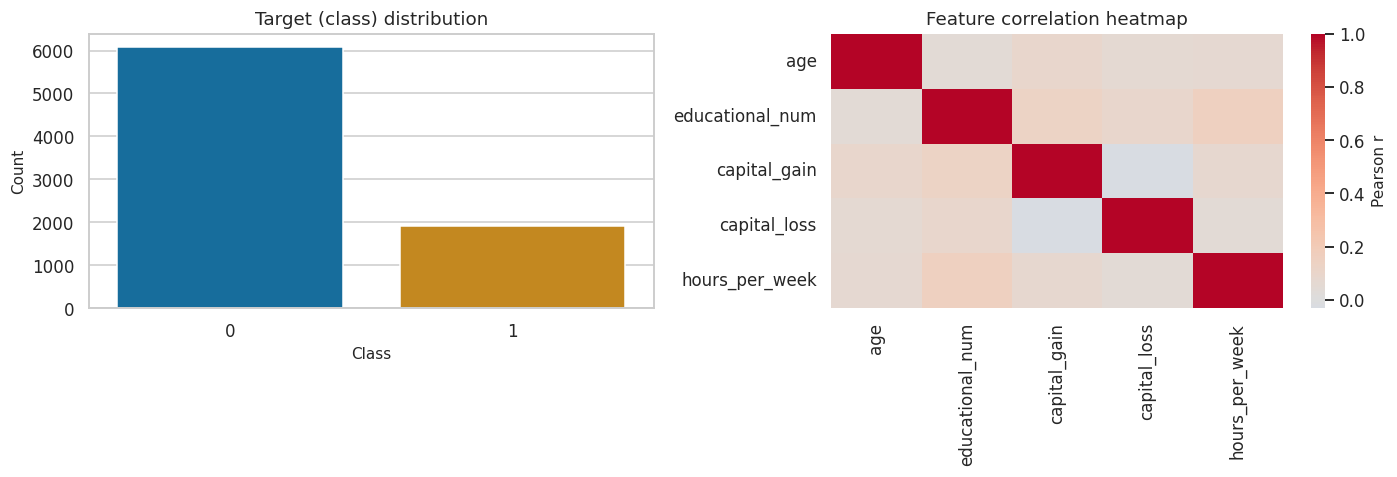

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(x=TARGET, data=df, ax=axes[0], hue=TARGET, legend=False)
axes[0].set_title("Target (class) distribution"); axes[0].set_xlabel("Class"); axes[0].set_ylabel("Count")
corr = df.drop(columns=TARGET).select_dtypes("number").corr()
sns.heatmap(corr, cmap="coolwarm", center=0, ax=axes[1], cbar_kws={"label": "Pearson r"})
axes[1].set_title("Feature correlation heatmap")
plt.tight_layout(); plt.savefig("../figures/clf_eda.png", bbox_inches="tight"); plt.show()

**Observation.**
- **Class imbalance:** about 76 % of people earn <=50K and 24 % earn >50K (6,086 vs 1,914 in the 8,000-row subsample). Always predicting <=50K already gives ~76 % accuracy, so we use a **stratified** split and **weighted** metrics (plus ROC-AUC) instead of relying on accuracy.
- **Data quality:** `workclass` (5.1 %), `occupation` (5.1 %) and `native_country` (1.8 %) have missing values, and 268 rows are exact duplicates (census records with identical attributes).
- **Correlations:** all pairwise correlations between the numeric features are weak (visually |r| < ~0.2; `capital_gain` and `capital_loss` are slightly negative), so multicollinearity is not a concern for Logistic Regression. This heatmap excludes the target and the categorical features, so which features drive income is judged later from the Random Forest importances (age, education years, hours per week, net capital, marital status).

## 3. Preprocessing (no data leakage)
Stratified 80:20 split **first**. Imputation, scaling and one-hot encoding live in a `ColumnTransformer` that is fitted on the **training set only** (inside a `Pipeline`, so every CV fold is leak-free too). Missing values (`?` in workclass, occupation, native_country) are imputed with the most frequent category.

**Engineered feature:** `net_capital = capital_gain - capital_loss` (a single signed measure of investment income; derived row-wise so it cannot leak).

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

df["net_capital"] = df["capital_gain"] - df["capital_loss"]          # engineered feature (row-wise)
X = df.drop(columns=TARGET); y = df[TARGET]
num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols); print("Categorical:", cat_cols)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])
def pipe(est): return Pipeline([("prep", make_preprocessor()), ("model", est)])     # preprocessing is re-fitted inside every fit/CV fold

classes = np.sort(y.unique()); n_classes = len(classes)
print(f"Train: {X_train.shape}  Test: {X_test.shape}  Classes: {n_classes}")
print("Train class %:", (y_train.value_counts(normalize=True).sort_index()*100).round(1).to_dict())
print("Test  class %:", (y_test.value_counts(normalize=True).sort_index()*100).round(1).to_dict())

Numeric: ['age', 'educational_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'net_capital']
Categorical: ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'gender', 'native_country']
Train: (6400, 13)  Test: (1600, 13)  Classes: 2
Train class %: {0: 76.1, 1: 23.9}
Test  class %: {0: 76.1, 1: 23.9}


## 4. Define all 10 classification algorithms
Part A = models 1–5 (Review 1), Part B = models 6–10 (Review 2). All use the **same** split and `random_state=42`.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier
from sklearn.neural_network import MLPClassifier

models = {
    # ---- Part A ----
    "Logistic Regression":   ("A", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "KNN":                   ("A", KNeighborsClassifier(n_neighbors=5)),
    "Gaussian Naive Bayes":  ("A", GaussianNB()),
    "Decision Tree":         ("A", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "SVM (SVC)":             ("A", SVC(probability=True, random_state=RANDOM_STATE)),
    # ---- Part B ----
    "Random Forest":         ("B", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)),
    "AdaBoost":              ("B", AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE)),
    "Gradient Boosting":     ("B", GradientBoostingClassifier(random_state=RANDOM_STATE)),
    "Bagging (DT base)":     ("B", BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE), n_estimators=100, random_state=RANDOM_STATE)),
    "MLP (Neural Net)":      ("B", MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=RANDOM_STATE)),
}
print(len(models), "algorithms defined")

10 algorithms defined


## 5. Train & evaluate all 10 algorithms (same test set)
Metrics: Accuracy, Precision / Recall / F1 (**weighted**), ROC-AUC (**One-vs-Rest** for multi-class), confusion matrix.

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

def evaluate(model, Xtr, ytr, Xte, yte):
    t0 = time.time(); model.fit(Xtr, ytr); fit_s = time.time() - t0
    pred = model.predict(Xte); proba = model.predict_proba(Xte)
    auc = roc_auc_score(yte, proba[:, 1]) if n_classes == 2 else roc_auc_score(yte, proba, multi_class="ovr", average="weighted")
    return {"Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred, average="weighted", zero_division=0),
            "Recall": recall_score(yte, pred, average="weighted", zero_division=0),
            "F1": f1_score(yte, pred, average="weighted"),
            "ROC-AUC (OvR)": auc, "Fit time (s)": fit_s}, confusion_matrix(yte, pred, labels=classes)

rows, cms = [], {}
for name, (part, mdl) in list(models.items()):
    mdl = pipe(mdl); models[name] = (part, mdl)   # wrap estimator with the leak-free preprocessor
    res, cm = evaluate(mdl, X_train, y_train, X_test, y_test)
    rows.append({"Algorithm": name, "Part": part, **res}); cms[name] = cm
results = pd.DataFrame(rows).set_index("Algorithm")
results_ranked = results.sort_values(["F1", "ROC-AUC (OvR)"], ascending=False)
results_ranked.insert(0, "Rank", range(1, len(results_ranked) + 1))
print("CONSOLIDATED 10-ALGORITHM COMPARISON (untuned, default / baseline hyperparameters, same 80:20 test split)")
display(results_ranked.round(4).style.background_gradient(cmap="Greens", subset=["Accuracy","Precision","Recall","F1","ROC-AUC (OvR)"]).format(precision=4))
results_ranked.round(4).to_csv("../figures/classification_comparison_untuned.csv")

CONSOLIDATED 10-ALGORITHM COMPARISON (untuned, default / baseline hyperparameters, same 80:20 test split)


,Rank,Part,Accuracy,Precision,Recall,F1,ROC-AUC (OvR),Fit time (s)
Algorithm,,,,,,,,
Gradient Boosting,1,B,0.8581,0.8518,0.8581,0.8515,0.9190,0.9892
SVM (SVC),2,A,0.8512,0.8441,0.8512,0.8436,0.9007,6.2383
Random Forest,3,B,0.8406,0.8330,0.8406,0.8346,0.8950,1.1975
Bagging (DT base),4,B,0.8356,0.8306,0.8356,0.8325,0.8876,2.5984
KNN,5,A,0.8350,0.8301,0.8350,0.8320,0.8655,0.0330
AdaBoost,6,B,0.8394,0.8306,0.8394,0.8310,0.9031,0.6018
Logistic Regression,7,A,0.8362,0.8285,0.8362,0.8303,0.9015,0.1406
MLP (Neural Net),8,B,0.8256,0.8231,0.8256,0.8243,0.8780,6.3967
Decision Tree,9,A,0.7994,0.8018,0.7994,0.8005,0.7379,0.0812


**Observation.**
- **Ranking:** Gradient Boosting is best (accuracy 0.858, F1 0.852, ROC-AUC 0.919), followed by SVC (F1 0.844) and Random Forest (0.835). Ranks 2–8 span only ≈ 2 F1 points (0.824–0.844).
- **Noise level:** with 1,600 test rows the standard error of accuracy is ≈ 0.9 points, so gaps below ≈ 1 point are not meaningful; only Gradient Boosting's ≈ 1-point lead and the clear failures below stand out.
- **Gaussian Naive Bayes collapses** (accuracy 0.318, AUC 0.589): after one-hot encoding many binary columns are dependent, breaking its independence/Gaussian assumptions, and it predicts >50K for 1,447 of 1,600 people (1,078 false positives).
- **Decision Tree** is next-worst (F1 0.800, AUC 0.738) because it overfits; its ensembles Bagging (AUC 0.888) and Random Forest (0.895) recover most of that.

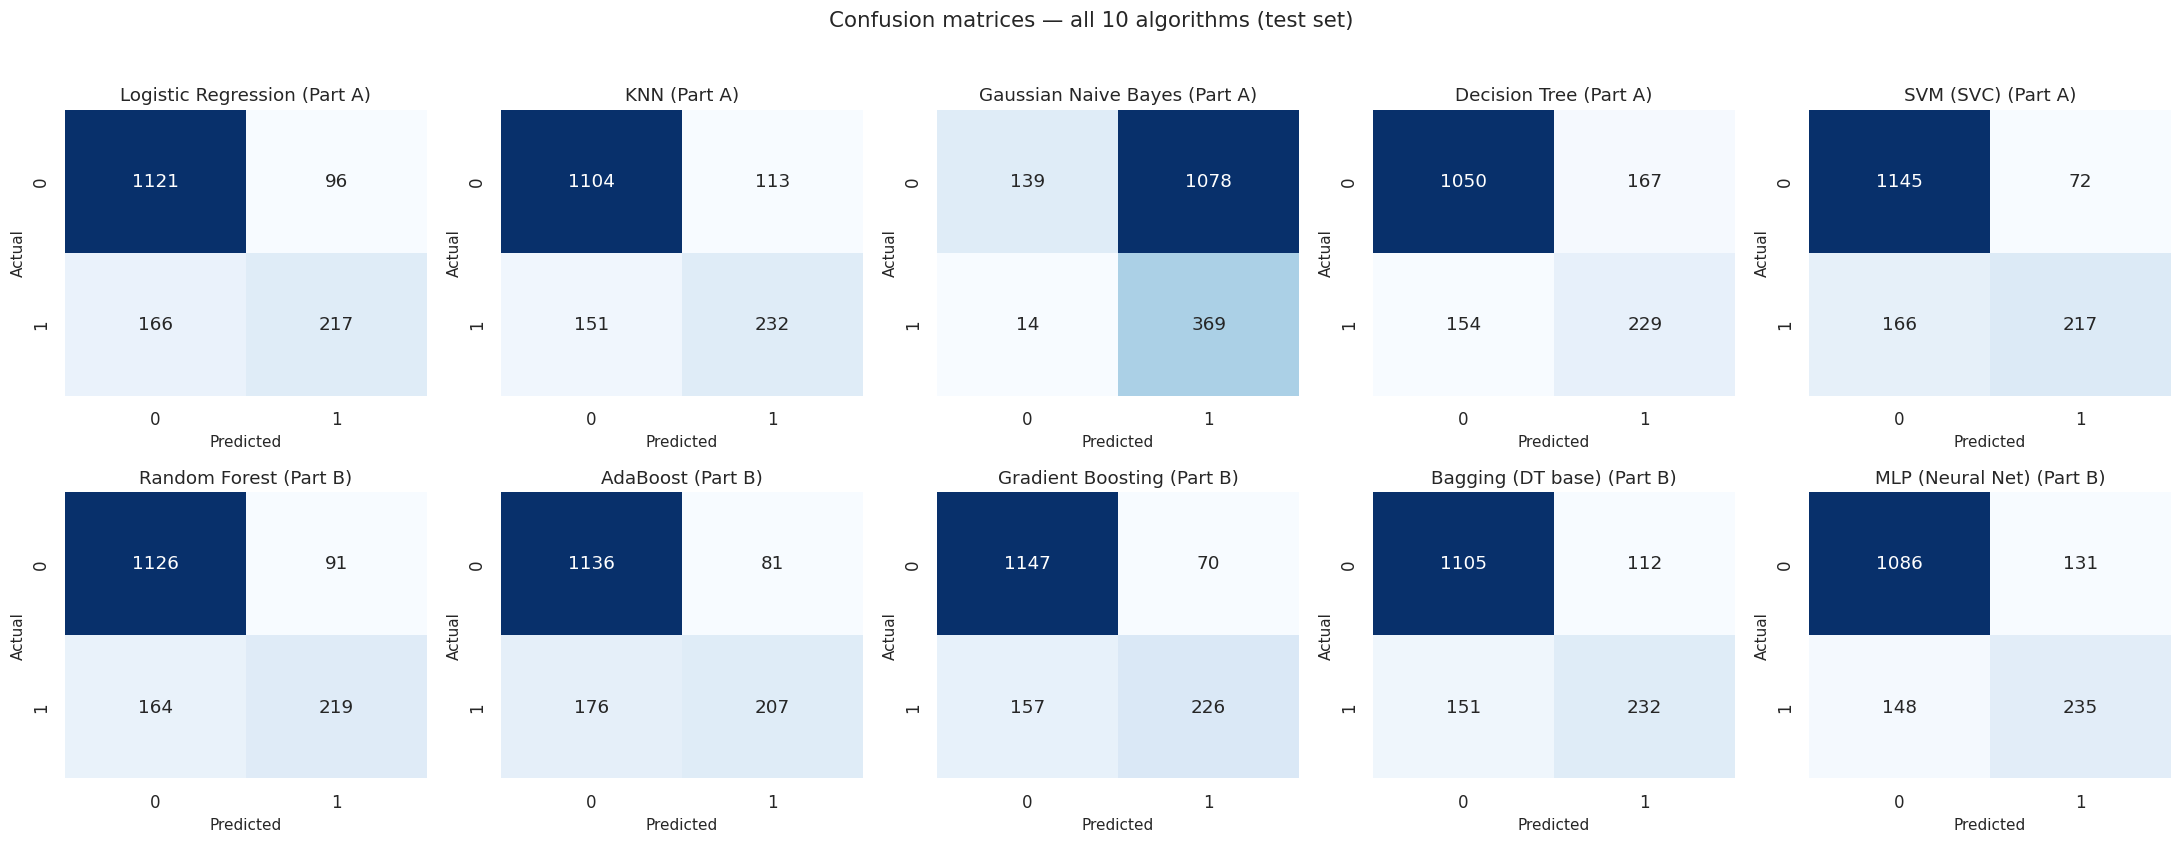

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for ax, (name, cm) in zip(axes.ravel(), cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=classes, yticklabels=classes)
    ax.set_title(f"{name} (Part {models[name][0]})"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
fig.suptitle("Confusion matrices — all 10 algorithms (test set)", y=1.02, fontsize=14)
plt.tight_layout(); plt.savefig("../figures/clf_confusion_all.png", bbox_inches="tight"); plt.show()

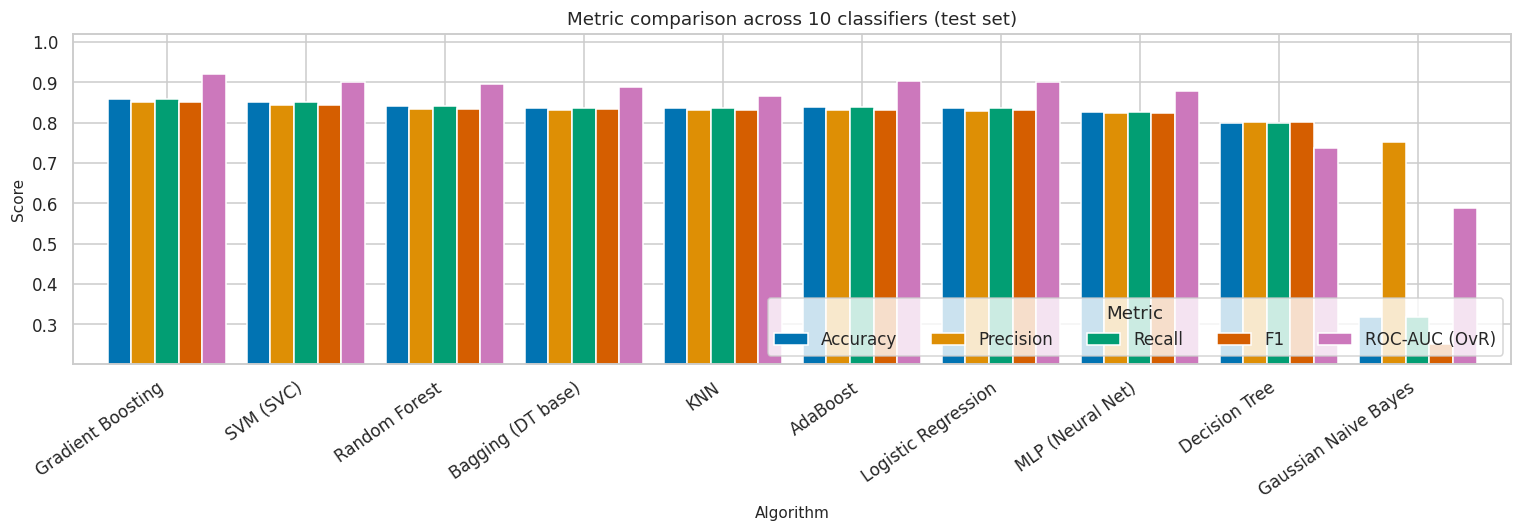

In [9]:
ax = results_ranked[["Accuracy","Precision","Recall","F1","ROC-AUC (OvR)"]].plot(kind="bar", figsize=(14, 5), width=0.85)
ax.set_title("Metric comparison across 10 classifiers (test set)"); ax.set_ylabel("Score"); ax.set_xlabel("Algorithm")
ax.set_ylim(min(0.8, results_ranked[["Accuracy","F1"]].min().min() - 0.05), 1.02)
plt.xticks(rotation=35, ha="right"); plt.legend(loc="lower right", ncol=5, title="Metric")
plt.tight_layout(); plt.savefig("../figures/clf_metric_bars.png", bbox_inches="tight"); plt.show()

**Observation.** Because of the 76/24 imbalance, weighted Precision, Recall and F1 are dominated by the majority class (weighted recall equals accuracy) and track accuracy closely. **ROC-AUC separates the models best:** Gradient Boosting (0.919), AdaBoost (0.903), Logistic Regression (0.902) and SVC (0.901) reach ≈ 0.90–0.92, while MLP (0.878), KNN (0.866) and especially the single tree (0.738) are lower. Naive Bayes is the clear outlier on every metric (accuracy 0.32, AUC 0.59); its weighted precision (0.75) is the least affected.

### 5.1 Model-specific interpretation visuals (required by the algorithm notes)

In [ ]:
# Random Forest feature importances (own figure so the decision tree below can get a full-size canvas)
rf_pipe = models["Random Forest"][1]; feat_names = rf_pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=[n.split("__", 1)[-1] for n in feat_names]).sort_values().tail(15)   # top 15 encoded features
fig, ax = plt.subplots(figsize=(9, 6))
imp.plot(kind="barh", ax=ax, color=sns.color_palette("colorblind")[0])
ax.set_title("Random Forest — top-15 feature importances"); ax.set_xlabel("Importance (mean decrease in impurity)"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.savefig("../figures/clf_rf_importance.png", bbox_inches="tight"); plt.show()

In [ ]:
dt = models["Decision Tree"][1].named_steps["model"]      # the (unconstrained) Part-A Decision Tree from Section 5
# Decision tree drawn in its OWN large figure. The width is increased automatically until no two node boxes overlap.
from itertools import combinations
feat_names = models["Random Forest"][1].named_steps["prep"].get_feature_names_out()
short_names = [n.split("__", 1)[-1] for n in feat_names]                    # drop the 'num__' / 'cat__' prefixes (display only)

def count_overlaps(fig, ax):
    fig.canvas.draw(); rend = fig.canvas.get_renderer()
    boxes = [(t.get_bbox_patch() or t).get_window_extent(rend) for t in ax.texts]     # one box per tree node
    return sum(a.overlaps(b) for a, b in combinations(boxes, 2))

for width in (26, 32, 38, 46, 56, 68):
    fig, ax = plt.subplots(figsize=(width, max(9, width * 0.30)))
    plot_tree(dt, feature_names=short_names, class_names=[str(c) for c in classes], filled=True, max_depth=3,
              fontsize=9, precision=2, impurity=False, proportion=False, ax=ax)
    n_over = count_overlaps(fig, ax)
    if n_over == 0:
        break
    plt.close(fig)
ax.set_title("Decision Tree (top 3 levels shown; numeric thresholds are in standardised units)", fontsize=14)
fig.savefig("../figures/clf_decision_tree.png", bbox_inches="tight", dpi=130); plt.show()
print(f"Figure width {width} in | overlapping node boxes: {n_over} | tree depth: {dt.get_depth()} | leaves: {dt.get_n_leaves()}")


**Decision Tree (top 3 levels, full-size image saved by the cell above).** Numeric thresholds are in standardised units. This image is loaded from `figures/clf_decision_tree.png`, so it also shows on GitHub when that file is committed.

![Decision tree (top 3 levels)](../figures/clf_decision_tree.png)

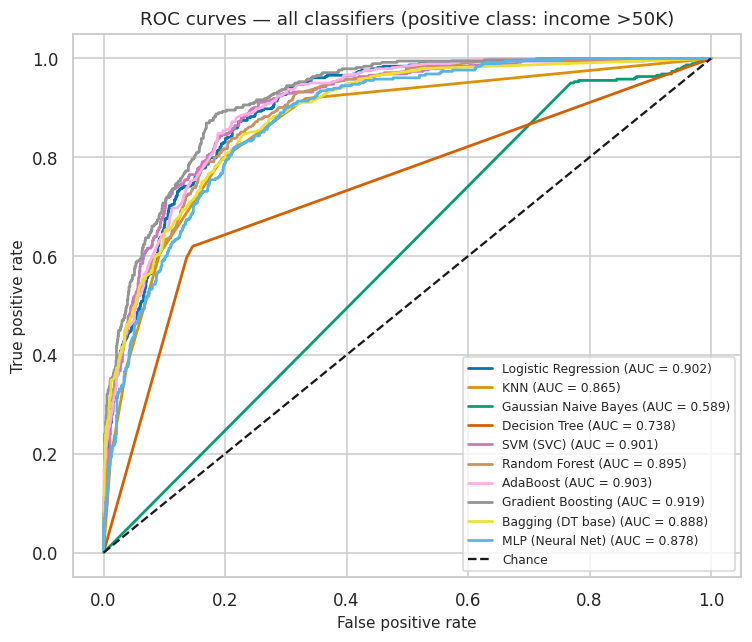

In [11]:
# ROC curves of ALL 10 models (binary problem: positive class = income >50K)
from sklearn.metrics import roc_curve, auc
fig, ax = plt.subplots(figsize=(7, 6))
for name, (part, mdl) in models.items():
    fpr, tpr, _ = roc_curve(y_test, mdl.predict_proba(X_test)[:, 1]); ax.plot(fpr, tpr, lw=1.8, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Chance"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves — all classifiers (positive class: income >50K)"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig("../figures/clf_roc_ovr.png", bbox_inches="tight"); plt.show()

## 6. Hyperparameter tuning (GridSearchCV, 5-fold stratified, scoring = weighted F1)
Tuning is done **inside a Pipeline** (scaler + model) on the **training set only**, so CV folds never see leaked scaling statistics. The test set is used once, for reporting.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grids = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), {"model__C": [0.1, 1, 10]}),
    "KNN":                 (KNeighborsClassifier(), {"model__n_neighbors": [5, 11, 21], "model__metric": ["euclidean", "manhattan"]}),
    "SVM (SVC)":           (SVC(probability=True, random_state=RANDOM_STATE), {"model__C": [1, 10], "model__kernel": ["rbf"]}),
    "Random Forest":       (RandomForestClassifier(random_state=RANDOM_STATE), {"model__n_estimators": [100, 300], "model__max_depth": [None, 10, 20]}),
    "AdaBoost":            (AdaBoostClassifier(random_state=RANDOM_STATE), {"model__n_estimators": [50, 200], "model__learning_rate": [0.5, 1.0]}),
    "Gradient Boosting":   (GradientBoostingClassifier(random_state=RANDOM_STATE), {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1], "model__max_depth": [2, 3]}),
    "MLP (Neural Net)":    (MLPClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE), {"model__hidden_layer_sizes": [(32,), (64, 32)], "model__activation": ["relu", "tanh"], "model__alpha": [1e-4, 1e-2]}),
}
tuned, tune_rows = {}, []
for name, (est, grid) in grids.items():
    base_cv = cross_val_score(pipe(est), X_train, y_train, cv=skf, scoring="f1_weighted").mean()   # default hyperparameters
    gs = GridSearchCV(pipe(est), grid, cv=skf, scoring="f1_weighted", n_jobs=-1).fit(X_train, y_train)
    pred = gs.predict(X_test); tuned[name] = gs
    tune_rows.append({"Algorithm": name, "CV F1 (default)": base_cv, "CV F1 (tuned)": gs.best_score_, "CV gain": gs.best_score_ - base_cv,
                      "Test F1 (tuned)": f1_score(y_test, pred, average="weighted"), "Test Acc (tuned)": accuracy_score(y_test, pred),
                      "Best params": {k.replace("model__", ""): v for k, v in gs.best_params_.items()}})
tune_df = pd.DataFrame(tune_rows).set_index("Algorithm").sort_values("CV F1 (tuned)", ascending=False)
display(tune_df.round(4)); tune_df.round(4).to_csv("../figures/classification_tuning.csv")

,CV F1 (default),CV F1 (tuned),CV gain,Test F1 (tuned),Test Acc (tuned),Best params
Algorithm,,,,,,
Gradient Boosting,0.8498,0.8500,0.0002,0.8540,0.8594,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti..."
Random Forest,0.8366,0.8478,0.0111,0.8457,0.8531,"{'max_depth': 20, 'n_estimators': 100}"
AdaBoost,0.8355,0.8414,0.0059,0.8342,0.8425,"{'learning_rate': 1.0, 'n_estimators': 200}"
MLP (Neural Net),0.8373,0.8380,0.0007,0.8478,0.8481,"{'activation': 'relu', 'alpha': 0.0001, 'hidde..."
SVM (SVC),0.8369,0.8369,0.0000,0.8436,0.8512,"{'C': 1, 'kernel': 'rbf'}"
Logistic Regression,0.8335,0.8339,0.0004,0.8325,0.8381,{'C': 10}
KNN,0.8230,0.8300,0.0071,0.8357,0.8419,"{'metric': 'manhattan', 'n_neighbors': 21}"


**Observation.** Gains are measured by 5-fold CV on the training set and are **small**: Random Forest +0.011 (`max_depth=20`), KNN +0.007 (k=21, Manhattan), AdaBoost +0.006, and ≈ 0 for Gradient Boosting (+0.0002), SVC (0.000), MLP (+0.0007) and Logistic Regression (+0.0004), so the defaults were already near the ceiling for these features. After tuning, Gradient Boosting (0.850) and Random Forest (0.848) are essentially tied, with the others 1–2 points behind (AdaBoost 0.841, MLP 0.838, SVC 0.837, LR 0.834, KNN 0.830); differences this small should not be over-interpreted.

## 7. 5-fold cross-validation for the two best models

In [13]:
top2 = tune_df.index[:2].tolist()
cv_rows = []
for name in top2:
    best_est = tuned[name].best_estimator_
    for metric in ["accuracy", "f1_weighted"]:
        s = cross_val_score(best_est, X_train, y_train, cv=skf, scoring=metric)
        cv_rows.append({"Algorithm": name, "Metric": metric, "Fold scores": np.round(s, 3).tolist(), "Mean": s.mean(), "Std": s.std()})
cv_df = pd.DataFrame(cv_rows); display(cv_df.round(4)); cv_df.round(4).to_csv("../figures/classification_cv_top2.csv", index=False)

,Algorithm,Metric,Fold scores,Mean,Std
0,Gradient Boosting,accuracy,"[0.855, 0.853, 0.846, 0.851, 0.87]",0.8552,0.0082
1,Gradient Boosting,f1_weighted,"[0.852, 0.846, 0.837, 0.846, 0.868]",0.8500,0.0103
2,Random Forest,accuracy,"[0.857, 0.846, 0.848, 0.848, 0.871]",0.8541,0.0093
3,Random Forest,f1_weighted,"[0.853, 0.839, 0.838, 0.841, 0.868]",0.8478,0.0116


## 8. Final consolidated table — untuned vs tuned (all 10 algorithms)
Algorithms with no tuning grid (Naive Bayes, Decision Tree, Bagging) keep their baseline results.

In [14]:
final = results[["Part","Accuracy","Precision","Recall","F1","ROC-AUC (OvR)"]].copy()
final.columns = ["Part"] + [f"{c} (base)" for c in final.columns[1:]]
tuned_metrics = {}
for name, gs in tuned.items():
    pred, proba = gs.predict(X_test), gs.predict_proba(X_test)
    tuned_metrics[name] = {"Accuracy (tuned)": accuracy_score(y_test, pred), "Precision (tuned)": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall (tuned)": recall_score(y_test, pred, average="weighted", zero_division=0), "F1 (tuned)": f1_score(y_test, pred, average="weighted"),
        "ROC-AUC (tuned)": roc_auc_score(y_test, proba[:, 1]) if n_classes == 2 else roc_auc_score(y_test, proba, multi_class="ovr", average="weighted")}
final = final.join(pd.DataFrame(tuned_metrics).T)
final = final.sort_values("F1 (base)", ascending=False)
display(final.round(4)); final.round(4).to_csv("../figures/classification_final_table.csv")

,Part,Accuracy (base),Precision (base),Recall (base),F1 (base),ROC-AUC (OvR) (base),Accuracy (tuned),Precision (tuned),Recall (tuned),F1 (tuned),ROC-AUC (tuned)
Algorithm,,,,,,,,,,,
Gradient Boosting,B,0.8581,0.8518,0.8581,0.8515,0.9190,0.8594,0.8535,0.8594,0.8540,0.9212
SVM (SVC),A,0.8512,0.8441,0.8512,0.8436,0.9007,0.8512,0.8441,0.8512,0.8436,0.9007
Random Forest,B,0.8406,0.8330,0.8406,0.8346,0.8950,0.8531,0.8462,0.8531,0.8457,0.9098
Bagging (DT base),B,0.8356,0.8306,0.8356,0.8325,0.8876,NaN,NaN,NaN,NaN,NaN
KNN,A,0.8350,0.8301,0.8350,0.8320,0.8655,0.8419,0.8343,0.8419,0.8357,0.8937
AdaBoost,B,0.8394,0.8306,0.8394,0.8310,0.9031,0.8425,0.8341,0.8425,0.8342,0.9040
Logistic Regression,A,0.8362,0.8285,0.8362,0.8303,0.9015,0.8381,0.8307,0.8381,0.8325,0.9009
MLP (Neural Net),B,0.8256,0.8231,0.8256,0.8243,0.8780,0.8481,0.8475,0.8481,0.8478,0.9087
Decision Tree,A,0.7994,0.8018,0.7994,0.8005,0.7379,NaN,NaN,NaN,NaN,NaN


## 9. Final model selection
Selection criterion: **highest 5-fold CV weighted-F1 on the training set** (never the test set, to avoid selecting on the data we report on). The test set is then used once for the final report.

FINAL MODEL: Gradient Boosting
Best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
CV F1 (tuned) = 0.8500  |  CV gain vs default = +0.0002

Held-out test report:
               precision    recall  f1-score   support

           0      0.884     0.938     0.910      1217
           1      0.755     0.611     0.675       383

    accuracy                          0.859      1600
   macro avg      0.820     0.774     0.793      1600
weighted avg      0.853     0.859     0.854      1600



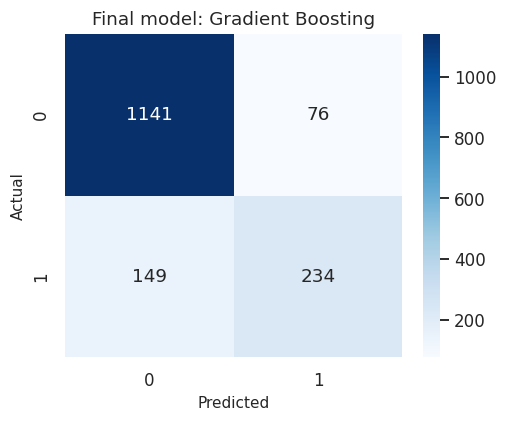

Saved ../models/best_classifier.joblib


In [15]:
best_name = tune_df["CV F1 (tuned)"].idxmax()
best_model = tuned[best_name].best_estimator_
pred = best_model.predict(X_test)
from sklearn.metrics import classification_report
print(f"FINAL MODEL: {best_name}\nBest params: {tune_df.loc[best_name, 'Best params']}")
print(f"CV F1 (tuned) = {tune_df.loc[best_name,'CV F1 (tuned)']:.4f}  |  CV gain vs default = {tune_df.loc[best_name,'CV gain']:+.4f}")
print("\nHeld-out test report:\n", classification_report(y_test, pred, digits=3))
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(confusion_matrix(y_test, pred, labels=classes), annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax)
ax.set_title(f"Final model: {best_name}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig("../figures/clf_final_confusion.png", bbox_inches="tight"); plt.show()

# Save for the GUI / deployment
joblib.dump({"model": best_model, "features": X_train.columns.tolist(), "classes": classes.tolist(), "class_labels": {0: "<=50K", 1: ">50K"},
             "model_name": best_name, "num_cols": num_cols, "cat_cols": cat_cols,
             "num_stats": X_train[num_cols].describe().loc[["min", "mean", "max"]].to_dict(),
             "cat_levels": {c: sorted(X_train[c].dropna().unique().tolist()) for c in cat_cols}}, "../models/best_classifier.joblib")
print("Saved ../models/best_classifier.joblib")

**Final model: Gradient Boosting** (200 trees, max depth 3, learning rate 0.1).

We picked it because it had the best 5-fold cross-validated weighted F1 on the training data (0.850). The test set played no part in the choice. On the unseen test set it gives accuracy 0.859, weighted F1 0.854 and ROC-AUC 0.921.

The confusion matrix shows where it falls short. It catches only about 61% of people who actually earn more than 50K (recall 0.61), and when it predicts '>50K' it is right about 76% of the time (precision 0.76). So roughly 4 in 10 high earners are missed. If finding high earners mattered most, we would lower the decision threshold or use class weights.

Compared with Logistic Regression, boosting is harder to interpret, but it is clearly better than a single decision tree and trains in a few seconds on this data.

## 10. Conclusions, limitations and trade-offs

**Which model won and why.** Gradient Boosting (200 trees, depth 3, learning rate 0.1) was selected because it had the highest 5-fold cross-validated weighted F1 on the training set (0.850). We chose it on cross-validation and not on the test set, so the test data stayed unseen until the final report. On the held-out test set (n = 1,600) it reached accuracy 0.859, weighted F1 0.854 and ROC-AUC 0.921. The majority-class baseline (always predicting '<=50K') already scores about 76%, so the model adds roughly 10 points of accuracy over doing nothing.

**How big are the differences between models?** Not very. After tuning, Gradient Boosting (F1 0.854), the MLP (0.848), Random Forest (0.846) and SVC (0.844) are all within about one F1 point of each other. In the 5-fold CV on the top two, Gradient Boosting (accuracy 0.855 +/- 0.008) and Random Forest (0.854 +/- 0.009) are statistically indistinguishable, because the gap is much smaller than the fold-to-fold spread. Tuning also helped very little (at most +0.011 CV-F1, for Random Forest), which suggests the default settings were already near the ceiling these features allow.

**Where the models struggled.**
- *Gaussian Naive Bayes* failed badly (accuracy 0.32, AUC 0.59). One-hot encoding creates many strongly dependent binary columns, which breaks its independence and Gaussian assumptions, and it over-predicts the >50K class.
- *The single Decision Tree* was the next weakest (F1 0.80, AUC 0.74) because it overfits. Its ensembles (Bagging and Random Forest) recovered most of that, which is the variance-reduction effect we expected.
- *Class imbalance:* the final model has precision 0.76 but recall of only 0.61 on the >50K class, so about 4 in 10 high earners are missed. Overall accuracy hides this, which is why we also looked at weighted F1, ROC-AUC and the confusion matrix.

**Interpretability vs accuracy.** Logistic Regression scored about 2 F1 points lower (about 0.83 on the test set) and gives coefficients that are easy to explain. Gradient Boosting is more accurate but harder to explain, so if the result had to be justified to a non-technical audience, Logistic Regression would be a reasonable choice. Training cost was not a deciding factor on this data: every model trained in seconds on the 6,400-row training set (KNN and Logistic Regression in well under a second, SVC and the MLP in roughly 6-7 seconds with default settings), but SVC and the MLP would scale worse to the full 48,842 rows.

**Limitations.**
- We used a stratified 8,000-row subsample (6,400 for training) for speed; results on the full dataset may shift slightly.
- With 1,600 test rows, differences under about one point are still within noise.
- The data includes gender and race, so any real-world use would need a fairness review. The model may reproduce social biases present in the census data.
- Tuning grids were deliberately small to keep run time practical.

**What we would do next.**
1. Raise recall for the >50K class by lowering the decision threshold or using class weights, and choose the threshold from a precision-recall curve.
2. Run on the full dataset and compare with repeated or nested cross-validation for tighter model comparisons.
3. Try XGBoost or LightGBM and wider hyperparameter searches.
4. Check fairness by comparing error rates across gender and race groups.